# Links

GitHub repository:
https://github.com/nylandgit/IND320-Repo

Streamlit app:
https://nylandgit-ind320-repo.streamlit.app/

Code runthrough video:


# References

In the interest of avoiding claims of self-plagiarism (don't know if this is necessary for IND320?):

Bulks of the following code is copied and adapted from Thor Martin Nyland's Project Work Part 1. Parts of the code is copied directly without any modification. The AI Statement is copied directly, as there has been no change in AI usage since Part 1.

Parts of the code have been copied from khliland's IND320 GitHub Repository. These parts are highlighted where applicable.

# AI Statement and Descriptive Log

## AI Statement

This project has used the free VS Code Copilot generative AI to: Generate code, identify bugs, fix bugs, brainstorm technical solutions, and to teach the process of coding through in-depth explanations of each generated line of code. Some Google searches have also involved Google's built-in generative AI.

The project author has steered the AI's coding through accepting, rejecting, and modifying the AI's code based on the author's intuition. The author has requested code explanations, studied the AI's code, and made explanatory comments for each code block based on the author's understanding.

The code provided is therefore created partly by the author and partly by generative AI. The explanatory code comments are written exclusively by the author.

## Descriptive Log

### Section 1: Random Sampling of Shapefiles and Open-Meteo API Data Retreival
* Copied and adapted the Atlas NVE shapefiles sampling example from class. Developed working demo for Precipitation Area sampling.
* Developed working demo for Electricity Area sampling.
* Developed working demo(s) for Open-Meteo API data retreival based on Electricity Area samples. Built function download_region(region, start_date, end_date). The code is bloated and uncommented, will revise and explain code after plots are made and I understand the project requirements more deeply.
* Discovered that the Open-Meteo API demo only works for small time periods (max two months), as the number of retreived rows R = h_per_day x days_2024 x n = 24 x 366 x 1000 = too much data for Open-Meteo's free plan.
* Reviewed Open-Meteo's limit documentation. Exactly one 2024 hourly download would fit within the 24h window, but the retreival would take hours, as there is also an hourly weight limit. This also leaves no room for tests during development.
* Spent a very long time troubleshooting, trying other solutions. AI solutions mostly suck, makes me happy :) I would personally disregard the hourly data and instead care only about daily averages, as Magasinstatistikk already does, but the task text requires hourly data specifically. I assume this is related to later tasks and therefore not skipable.
* Temporarily skipped the data retreival for all of 2024. Using only January-March 2024. Returning here after the rest of the work is done.

<p></p>
<p></p>

### Plots
* Made plot of average precipitation as a function of time.


# Non-Streamlit Code

## 1. Atlas NVE, Open-Meteo API

### 1.1 WIP Precipitation Area Sampling

In [1]:
# This code has been copied and adapted from Kristian Hovde Lilands IND320
# lecture held at NMBU on 26.10.2026.
import geopandas as gpd

# Read file
gdf_precip = gpd.read_file("../shapefiles/precipitation areas/NVE_Region.shp")

# Generate random points
n = 1000
points_precip = gdf_precip['geometry'].sample_points(size=n, random_state=42)

# Transform WGS84 (EPSG:4326) for latitude and longitude (?)
points_wgs84_precip = points_precip.to_crs(epsg=4326)

# Extract coordinates and print
for idx_precip, multipoint_precip in points_wgs84_precip.items():
    region_name_precip = gdf_precip.loc[idx_precip, 'REGION']
    #print(f"Region: {region_name_precip}")

    for point_precip in multipoint_precip.geoms:
        # Do something more useful with the coordinates than this (?)
        lat_precip = point_precip.y
        lon_precip = point_precip.x

print(lat_precip)


59.88203442160552


### 1.2 WIP Electricity Areas Sampling

In [ ]:
# This code has been copied and adapted from Kristian Hovde Lilands IND320
# lecture held at NMBU on 26.10.2026.

import geopandas as pd
import pandas as gpd

# Read file
gdf_el = gpd.read_file("../shapefiles/electricity areas/Budområder.shp")

# Generate random points
n = 1000
points_el = gdf_el['geometry'].sample_points(size=n, random_state=42)

# Transform WGS84 (EPSG:4326) for latitude and longitude (?)
points_wgs84_el = points_el.to_crs(epsg=4326)

# Extract coordinates and save them
locations_by_region_el = {}
for idx_el, multipoint_el in points_wgs84_el.items():
    region_name_el = gdf_el.loc[idx_el, 'budomr']
    print(f"Region: {region_name_el}")

    for point_el in multipoint_el.geoms:
        # Do something more useful with the coordinates than this (?)
        lat_el = point_el.y
        lon_el = point_el.x
        locations_by_region_el.setdefault(region_name_el, []).append((lat_el, lon_el))

df_el = pd.DataFrame(locations_by_region_el)


Region: NO 1
Region: NO 2
Region: NO 3
Region: NO 4
Region: NO 5


In [3]:


print(lat_el)
print(df_el["NO 3"].tail())


60.83102092763396
995     (62.39817414913064, 8.756255265888164)
996    (62.484175573172365, 7.969093514014246)
997    (62.630779420709025, 8.370873680643552)
998      (62.72342755382862, 6.48487924858975)
999      (62.21626138111599, 5.23862720022732)
Name: NO 3, dtype: object


### 1.3 download_region()

In [4]:
# The following code has been adapted from Open Meteo's Python coding
# example at https://open-meteo.com/en/docs/historical-forecast-api.
import openmeteo_requests

import pandas as pd
import requests_cache
from retry_requests import retry

# Setting up Open-Meteo API client with cache and retry on error.
cache_session = requests_cache.CachedSession('.cache', expire_after = -1)
retry_session = retry(cache_session, retries = 5, backoff_factor = 0.2)
openmeteo = openmeteo_requests.Client(session = retry_session)

# Defining function with input parameters as instructed.
def download_region(region, start_date, end_date):
    url = "https://archive-api.open-meteo.com/v1/archive"
    region_data = []

    # Setting up chunk-based API data requesting (lots of data).
    locations = locations_by_region_el[region]
    chunk_size = 10
    total_chunks = (len(locations) + chunk_size - 1) // chunk_size

    # Iterating over each randomly sampled point corresponding to selected
    # region, in our case "NO 3".
    for chunk_number, chunk_start in enumerate(
        range(0, len(locations), chunk_size), start=1):
        
        chunk = locations[chunk_start:chunk_start + chunk_size]

        # Defining parameters as instructed by Open-Meteo API.
        params = {
            "latitude": [lat_el for lat_el, lon_el in chunk],
            "longitude": [lon_el for lat_el, lon_el in chunk],
            "start_date": start_date,
            "end_date": end_date,
            "hourly": ["temperature_2m", "precipitation", "surface_pressure"],
            "models": "era5",
            "timezone": "Europe/Berlin",
        }

        print(
            f"Attempting chunk {chunk_number}/{total_chunks} "
            f"({len(chunk)} points) for region {region}...",
            flush=True,
        )

        # Requesting data from API. API sends data as objects in Python list,
        # [0] selects first object explicitly as .Hourly() does not work on
        # Python lists.
        responses = openmeteo.weather_api(url, params=params)
        
        for (lat_el, lon_el), response in zip(chunk, responses):
            hourly = response.Hourly()

            # Creating dictionary to be populated with data from API.
            hourly_data = {

                # Defining "date" key:value pair(s), this is converted to a df
                # column later. Essentially, this block defines the "date"
                # column in our soon-to-exist df. Methodology is from API.
                "date": pd.date_range(
                    start=pd.to_datetime(hourly.Time(), unit="s", utc=True),
                    end=pd.to_datetime(hourly.TimeEnd(), unit="s", utc=True),
                    freq=pd.Timedelta(seconds=hourly.Interval()),
                    inclusive="left",
                ).tz_convert(response.Timezone().decode()),

                # Defining temp. and precip. columns for soon-to-exist df.
                "temperature_2m": hourly.Variables(0).ValuesAsNumpy(),
                "precipitation": hourly.Variables(1).ValuesAsNumpy(),
                #"surface_pressure": hourly.Variables(2).ValuesAsNumpy(),
            }

            # Converting data dictionary to pandas df.
            point_data = pd.DataFrame(data=hourly_data)
            #point_data["latitude"] = lat_el
            #point_data["longitude"] = lon_el
            region_data.append(point_data)

        print(f"Completed chunk {chunk_number}/{total_chunks}.", flush=True)

    return pd.concat(region_data, ignore_index=True)

no3_2024 = download_region("NO 3", "2024-01-01", "2024-01-31")


Attempting chunk 1/100 (10 points) for region NO 3...
Completed chunk 1/100.
Attempting chunk 2/100 (10 points) for region NO 3...
Completed chunk 2/100.
Attempting chunk 3/100 (10 points) for region NO 3...
Completed chunk 3/100.
Attempting chunk 4/100 (10 points) for region NO 3...
Completed chunk 4/100.
Attempting chunk 5/100 (10 points) for region NO 3...
Completed chunk 5/100.
Attempting chunk 6/100 (10 points) for region NO 3...
Completed chunk 6/100.
Attempting chunk 7/100 (10 points) for region NO 3...
Completed chunk 7/100.
Attempting chunk 8/100 (10 points) for region NO 3...
Completed chunk 8/100.
Attempting chunk 9/100 (10 points) for region NO 3...
Completed chunk 9/100.
Attempting chunk 10/100 (10 points) for region NO 3...
Completed chunk 10/100.
Attempting chunk 11/100 (10 points) for region NO 3...
Completed chunk 11/100.
Attempting chunk 12/100 (10 points) for region NO 3...
Completed chunk 12/100.
Attempting chunk 13/100 (10 points) for region NO 3...
Completed chunk

In [5]:
print(no3_2024)

print(len(locations_by_region_el["NO 3"]))




                            date  temperature_2m  precipitation
0      2024-01-01 00:00:00+01:00            0.75            0.0
1      2024-01-01 01:00:00+01:00            0.60            0.0
2      2024-01-01 02:00:00+01:00            0.55            0.0
3      2024-01-01 03:00:00+01:00            0.55            0.0
4      2024-01-01 04:00:00+01:00            0.50            0.0
...                          ...             ...            ...
743995 2024-01-31 19:00:00+01:00            4.25            0.3
743996 2024-01-31 20:00:00+01:00            4.50            0.4
743997 2024-01-31 21:00:00+01:00            3.20            0.7
743998 2024-01-31 22:00:00+01:00            3.10            1.5
743999 2024-01-31 23:00:00+01:00            2.65            1.4

[744000 rows x 3 columns]
1000


## 2. Plotting

### 2.1 Plotting Average Precipitation as Function of Time

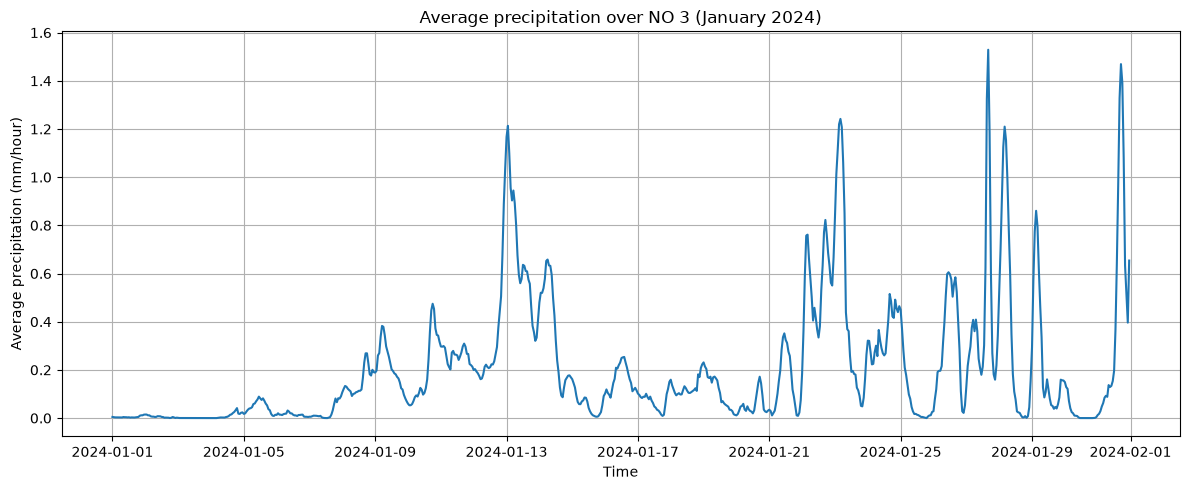

date
2024-01-01 00:00:00+01:00    0.0047
2024-01-01 01:00:00+01:00    0.0038
2024-01-01 02:00:00+01:00    0.0030
2024-01-01 03:00:00+01:00    0.0030
2024-01-01 04:00:00+01:00    0.0030
Name: precipitation, dtype: float32


In [19]:
import matplotlib.pyplot as plt

# Taking the average hourly precipitation across all 1000 sampled points.
precip_avg = no3_2024.groupby("date")["precipitation"].mean().sort_index()

# Plotting.
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(precip_avg.index, precip_avg.values)

ax.set(
    title="Average precipitation over NO 3 (January 2024)",
    xlabel="Time",
    ylabel="Average precipitation (mm/hour)",
)
ax.grid(True)
fig.tight_layout()
plt.show()

print(precip_avg.head())

### 2.2 Discrete Cosine Transform

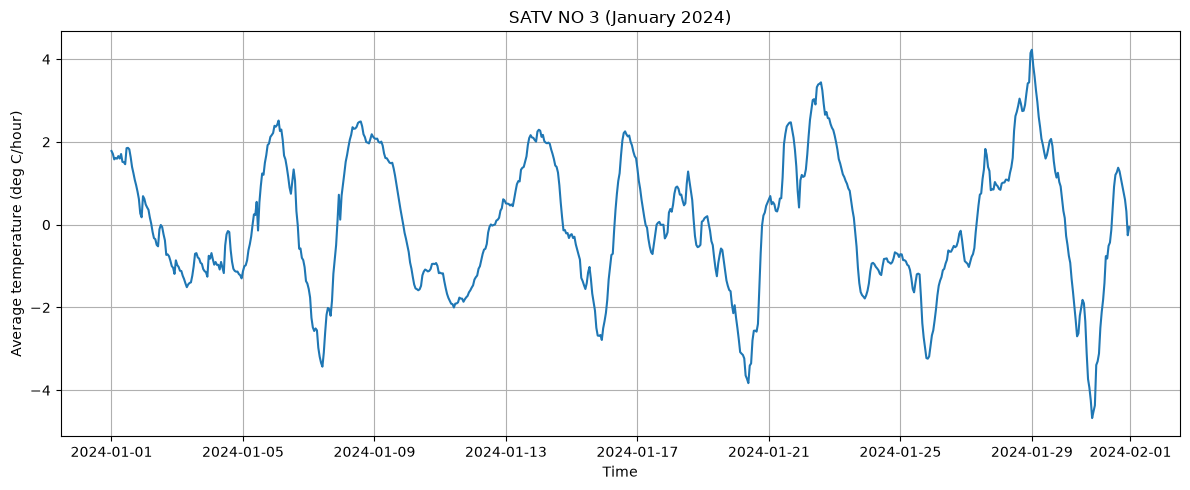

In [31]:
import numpy as np
from scipy.fft import dct, idct

# Taking the average hourly temperature across all 1000 sampled points.
temp_avg = no3_2024.groupby("date")["temperature_2m"].mean().sort_index()

# Defining n = number of observations for avg temperature.
temp_avg_np = temp_avg.to_numpy(dtype=float)
n = len(temp_avg_np)

# Defining cutoff period and frequency.
cutoff_period_hours = 7 * 24
f = np.arange(n) / (2 * n)  # cycles per hourly sample


coefficients = dct(temp_avg_np, type=2, norm="ortho")
coefficients[f < 1 / cutoff_period_hours] = 0

high_pass_temp = pd.Series(
    idct(coefficients, type=2, norm="ortho"),
    index=temp_avg.index,
    name="high_pass_precipitation",
)

# Plotting.
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(high_pass_temp.index, high_pass_temp.values)

ax.set(
    title="SATV NO 3 (January 2024)",
    xlabel="Time",
    ylabel="Average temperature (deg C/hour)",
)
ax.grid(True)
fig.tight_layout()
plt.show()

